In [1]:
!pip install pennylane

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 55.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 33.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 41.1 MB/s eta 0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1


--- [KOD 4] KLASİK k-NN VE QKNN DENEYLERİ BAŞLATILIYOR ---
Toplam Örneklem: 144 (Sınıf 0: 48, Sınıf 1: 48, Sınıf 2: 48)
Eğitim Seti: 115 | Test Seti: 29

PCA İlk 4 Bileşenin Açıkladığı Varyans Oranları: [0.3855 0.1937 0.1069 0.0684]
Toplam Açıklanan Varyans: %75.45

--- [YÖNTEM 1] Klasik k-NN Çalıştırılıyor ---
--- [YÖNTEM 2] QKNN (Adjoint Kernel) Çalıştırılıyor ---
   -> Adjoint Mesafe Matrisi: 40/115 satır tamamlandı.
   -> Adjoint Mesafe Matrisi: 80/115 satır tamamlandı.
   -> Adjoint Mesafe Matrisi: 115/115 satır tamamlandı.
   -> Adjoint Mesafe Matrisi: 29/29 satır tamamlandı.

--- [YÖNTEM 3] QKNN (Swap Test Devresi - 9 Kübit) Çalıştırılıyor ---
   -> Swap Mesafe Matrisi: 40/115 satır tamamlandı.
   -> Swap Mesafe Matrisi: 80/115 satır tamamlandı.
   -> Swap Mesafe Matrisi: 115/115 satır tamamlandı.
   -> Swap Mesafe Matrisi: 29/29 satır tamamlandı.

--- 5-FOLD ÇAPRAZ DOĞRULAMA HESAPLANIYOR ---
QKNN Adjoint Tam Mesafe Matrisi hesaplanıyor...
   -> Adjoint Mesafe Matrisi: 40/144 sa

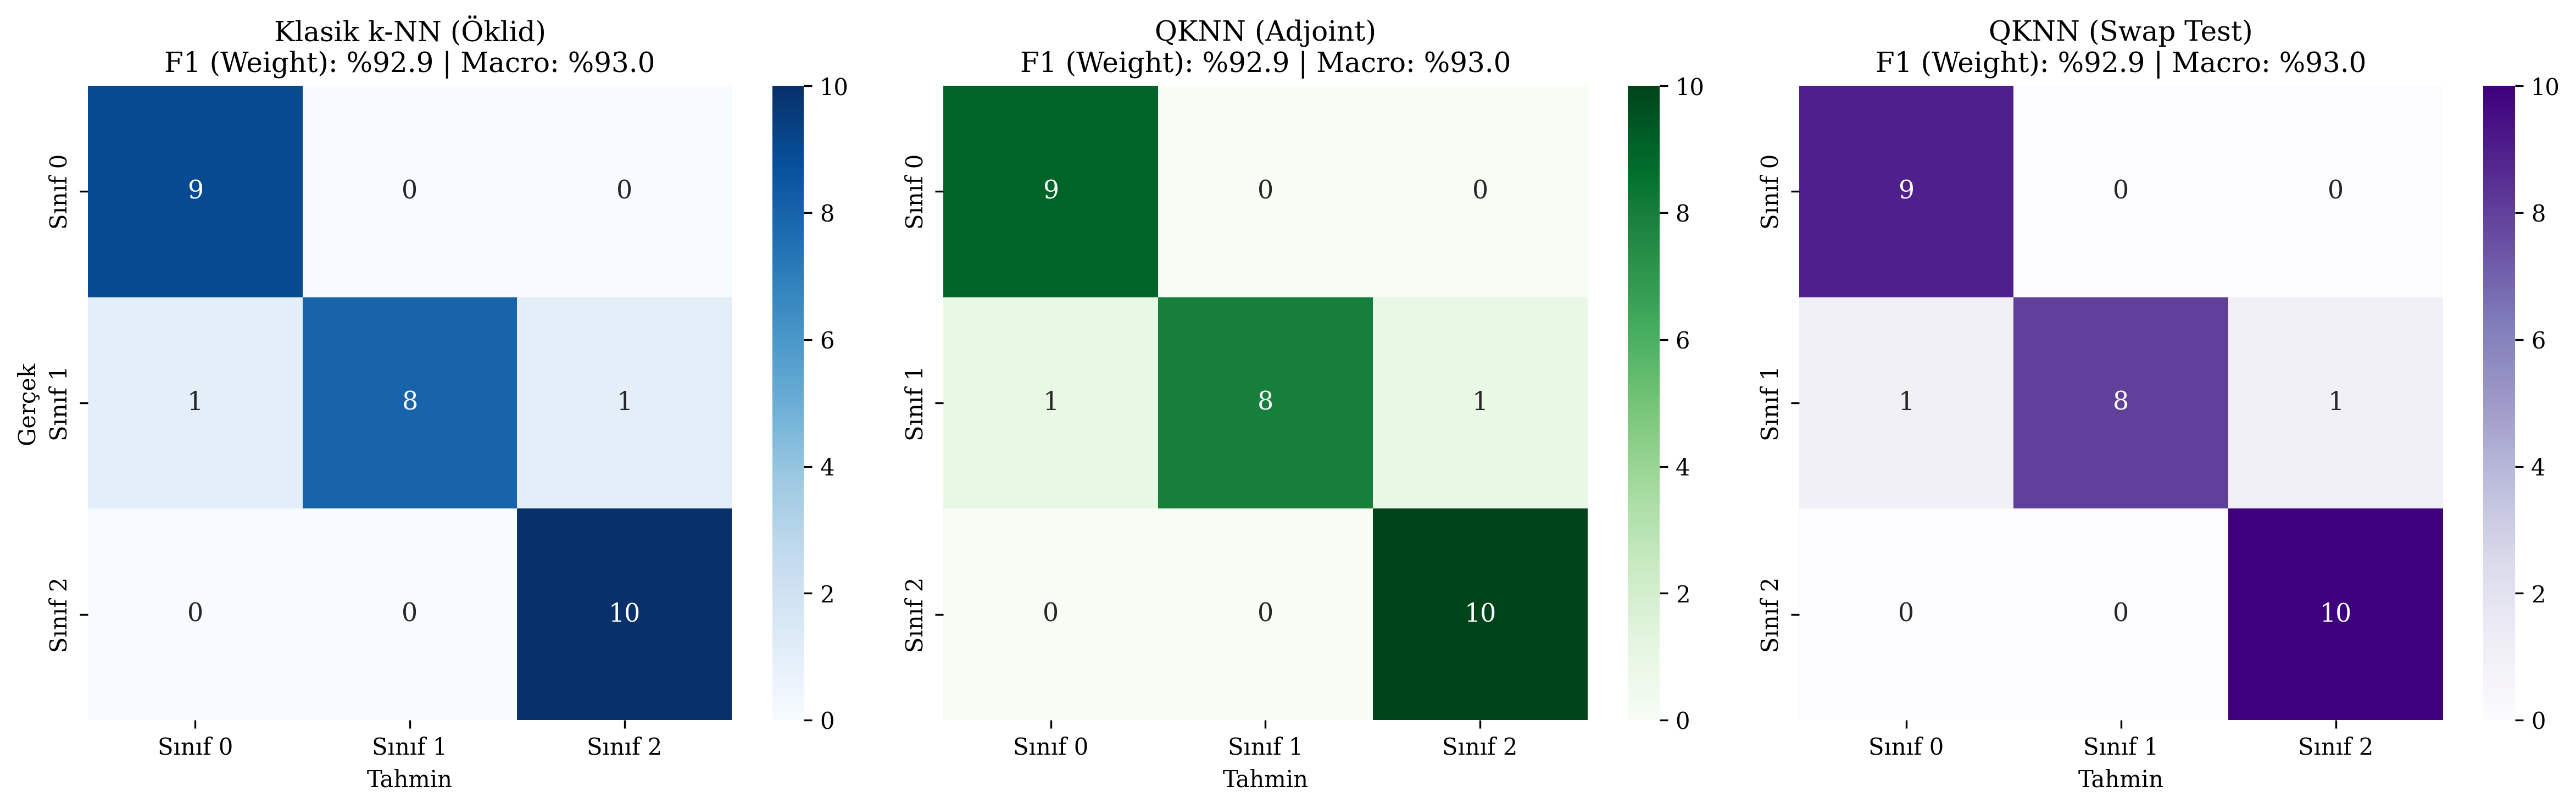

In [2]:
!pip install pennylane
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.datasets import load_wine # Wine veri seti eklendi

# ==========================================================
# 1. VERİ HAZIRLIĞI VE ÖRNEKLEME PROTOKOLÜ (HAKEM #2 YORUM #2)
# ==========================================================
print("--- [KOD 4] KLASİK k-NN VE QKNN DENEYLERİ BAŞLATILIYOR ---")

# Sadece veri seti değiştirildi (Wine - 3 Sınıflı)
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df["Class"] = wine.target

RANDOM_SEED = 42
# Wine veri setindeki en küçük sınıf 48 örneğe sahip olduğu için 48 seçildi
n_samples_per_class = 48

class_0 = df[df["Class"] == 0].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
class_1 = df[df["Class"] == 1].sample(n=n_samples_per_class, random_state=RANDOM_SEED)
class_2 = df[df["Class"] == 2].sample(n=n_samples_per_class, random_state=RANDOM_SEED)

df_balanced = (
    pd.concat([class_0, class_1, class_2])
    .sample(frac=1, random_state=RANDOM_SEED)
    .reset_index(drop=True)
)

cols_to_drop = [col for col in ["Time", "Class"] if col in df_balanced.columns]
X_raw = df_balanced.drop(columns=cols_to_drop).values
y = df_balanced["Class"].values

print(f"Toplam Örneklem: {len(X_raw)} (Sınıf 0: {np.sum(y == 0)}, Sınıf 1: {np.sum(y == 1)}, Sınıf 2: {np.sum(y == 2)})")

# ==========================================================
# 2. VERİ BÖLME VE VERİ SIZINTISINI ÖNLEME (HAKEM #2 YORUM #3)
# ==========================================================
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)
print(f"Eğitim Seti: {len(X_train_raw)} | Test Seti: {len(X_test_raw)}\n")

# A) Standardizasyon (Yalnızca train üzerinde fit)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# B) PCA 4 Boyut (Yalnızca train üzerinde fit)
n_qubits = 4
pca_4d = PCA(n_components=n_qubits, random_state=RANDOM_SEED)
X_train_4d = pca_4d.fit_transform(X_train_scaled)
X_test_4d = pca_4d.transform(X_test_scaled)

explained_variance = pca_4d.explained_variance_ratio_
total_var = np.sum(explained_variance) * 100
print(f"PCA İlk 4 Bileşenin Açıkladığı Varyans Oranları: {np.round(explained_variance, 4)}")
print(f"Toplam Açıklanan Varyans: %{total_var:.2f}\n")

# C) Kuantum Açısal Kodlama Normalizasyonu [-pi, pi] (Yalnızca train üzerinde fit)
minmax_scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_train_angles = minmax_scaler.fit_transform(X_train_4d)
X_test_angles = minmax_scaler.transform(X_test_4d)

k_neighbors = 5

# ==========================================================
# 3. YÖNTEM 1: KLASİK k-NN (ÖKLİD MESAFESİ)
# ==========================================================
print("--- [YÖNTEM 1] Klasik k-NN Çalıştırılıyor ---")
start_t = time.time()
knn_classic = KNeighborsClassifier(n_neighbors=k_neighbors, metric="minkowski", p=2)
knn_classic.fit(X_train_angles, y_train)
time_train_classic = time.time() - start_t

start_t = time.time()
preds_classic = knn_classic.predict(X_test_angles)
# 3 sınıf olduğu için predict_proba hepsini döndürmeli
probs_classic = knn_classic.predict_proba(X_test_angles)
time_test_classic = time.time() - start_t

acc_classic = accuracy_score(y_test, preds_classic)
# Multiclass desteklemesi için pos_label=1 yerine average="weighted" yapıldı, değişken adı korundu
f1_classic_bin = f1_score(y_test, preds_classic, average="weighted")
f1_classic_macro = f1_score(y_test, preds_classic, average="macro")
# Multiclass AUC için multi_class="ovr" eklendi
auc_classic = roc_auc_score(y_test, probs_classic, multi_class="ovr")

# ==========================================================
# 4. YÖNTEM 2: QKNN - ADJOINT DURUM SADAKATİ MESAFESİ
# ==========================================================
print("--- [YÖNTEM 2] QKNN (Adjoint Kernel) Çalıştırılıyor ---")
dev_adjoint = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev_adjoint, interface="autograd")
def adjoint_fidelity_qnode(x1, x2):
    qml.AngleEmbedding(x1, wires=range(n_qubits))
    qml.adjoint(qml.AngleEmbedding)(x2, wires=range(n_qubits))
    return qml.probs(wires=range(n_qubits))

def compute_adjoint_distance_matrix(X1, X2=None):
    if X2 is None:
        X2 = X1
        symmetric = True
    else:
        symmetric = False

    n1, n2 = len(X1), len(X2)
    D = np.zeros((n1, n2))

    for i in range(n1):
        for j in range(n2):
            if symmetric and j < i:
                D[i, j] = D[j, i]
            elif symmetric and i == j:
                D[i, j] = 0.0
            else:
                probs = adjoint_fidelity_qnode(X1[i], X2[j])
                val = np.clip(probs[0], 0.0, 1.0)
                D[i, j] = np.sqrt(np.maximum(0.0, 2.0 - 2.0 * val))

        if (i + 1) % 40 == 0 or i == n1 - 1:
            print(f"   -> Adjoint Mesafe Matrisi: {i+1}/{n1} satır tamamlandı.")

    return D

start_t = time.time()
D_train_adj = compute_adjoint_distance_matrix(X_train_angles)
time_train_adj = time.time() - start_t

start_t = time.time()
D_test_adj = compute_adjoint_distance_matrix(X_test_angles, X_train_angles)
time_test_adj = time.time() - start_t

knn_adjoint = KNeighborsClassifier(n_neighbors=k_neighbors, metric="precomputed")
knn_adjoint.fit(D_train_adj, y_train)

preds_adjoint = knn_adjoint.predict(D_test_adj)
probs_adjoint = knn_adjoint.predict_proba(D_test_adj)

acc_adjoint = accuracy_score(y_test, preds_adjoint)
f1_adjoint_bin = f1_score(y_test, preds_adjoint, average="weighted")
f1_adjoint_macro = f1_score(y_test, preds_adjoint, average="macro")
auc_adjoint = roc_auc_score(y_test, probs_adjoint, multi_class="ovr")

# ==========================================================
# 5. YÖNTEM 3: QKNN - 9 KÜBİTLİK SWAP-TEST DEVRESİ
# ==========================================================
print("\n--- [YÖNTEM 3] QKNN (Swap Test Devresi - 9 Kübit) Çalıştırılıyor ---")
dev_swap = qml.device("default.qubit", wires=(2 * n_qubits + 1))

@qml.qnode(dev_swap, interface="autograd")
def swap_test_qnode(x1, x2):
    qml.Hadamard(wires=0)
    qml.AngleEmbedding(x1, wires=range(1, n_qubits + 1))
    qml.AngleEmbedding(x2, wires=range(n_qubits + 1, 2 * n_qubits + 1))
    for i in range(n_qubits):
        qml.CSWAP(wires=[0, i + 1, i + n_qubits + 1])
    qml.Hadamard(wires=0)
    return qml.expval(qml.PauliZ(0))

def compute_swap_distance_matrix(X1, X2=None):
    if X2 is None:
        X2 = X1
        symmetric = True
    else:
        symmetric = False

    n1, n2 = len(X1), len(X2)
    D = np.zeros((n1, n2))

    for i in range(n1):
        for j in range(n2):
            if symmetric and j < i:
                D[i, j] = D[j, i]
            elif symmetric and i == j:
                D[i, j] = 0.0
            else:
                val = swap_test_qnode(X1[i], X2[j])
                val = np.clip(val, 0.0, 1.0)
                D[i, j] = np.sqrt(np.maximum(0.0, 2.0 - 2.0 * val))

        if (i + 1) % 40 == 0 or i == n1 - 1:
            print(f"   -> Swap Mesafe Matrisi: {i+1}/{n1} satır tamamlandı.")

    return D

start_t = time.time()
D_train_swap = compute_swap_distance_matrix(X_train_angles)
time_train_swap = time.time() - start_t

start_t = time.time()
D_test_swap = compute_swap_distance_matrix(X_test_angles, X_train_angles)
time_test_swap = time.time() - start_t

knn_swap = KNeighborsClassifier(n_neighbors=k_neighbors, metric="precomputed")
knn_swap.fit(D_train_swap, y_train)

preds_swap = knn_swap.predict(D_test_swap)
probs_swap = knn_swap.predict_proba(D_test_swap)

acc_swap = accuracy_score(y_test, preds_swap)
f1_swap_bin = f1_score(y_test, preds_swap, average="weighted")
f1_swap_macro = f1_score(y_test, preds_swap, average="macro")
auc_swap = roc_auc_score(y_test, probs_swap, multi_class="ovr")

# ==========================================================
# 6. İSTATİSTİKSEL ANALİZ: 5-FOLD CV (ROC-AUC DAHİL)
# ==========================================================
print("\n--- 5-FOLD ÇAPRAZ DOĞRULAMA HESAPLANIYOR ---")
scaler_all = StandardScaler()
pca_all = PCA(n_components=n_qubits, random_state=RANDOM_SEED)
minmax_all = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_all_angles = minmax_all.fit_transform(pca_all.fit_transform(scaler_all.fit_transform(X_raw)))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

print("QKNN Adjoint Tam Mesafe Matrisi hesaplanıyor...")
D_all_adj = compute_adjoint_distance_matrix(X_all_angles)

print("QKNN Swap Tam Mesafe Matrisi hesaplanıyor...")
D_all_swap = compute_swap_distance_matrix(X_all_angles)

metrics_classic_cv = {'acc': [], 'f1_bin': [], 'auc': []}
metrics_adjoint_cv = {'acc': [], 'f1_bin': [], 'auc': []}
metrics_swap_cv = {'acc': [], 'f1_bin': [], 'auc': []}

for train_idx, test_idx in cv.split(X_raw, y):
    y_tr, y_te = y[train_idx], y[test_idx]

    # 1. Klasik k-NN
    knn_c = KNeighborsClassifier(n_neighbors=k_neighbors, metric="euclidean")
    knn_c.fit(X_all_angles[train_idx], y_tr)
    preds_c = knn_c.predict(X_all_angles[test_idx])
    probs_c = knn_c.predict_proba(X_all_angles[test_idx])
    metrics_classic_cv['acc'].append(accuracy_score(y_te, preds_c))
    metrics_classic_cv['f1_bin'].append(f1_score(y_te, preds_c, average="weighted", zero_division=0))
    metrics_classic_cv['auc'].append(roc_auc_score(y_te, probs_c, multi_class="ovr"))

    # 2. QKNN (Adjoint Kernel)
    knn_adj = KNeighborsClassifier(n_neighbors=k_neighbors, metric="precomputed")
    knn_adj.fit(D_all_adj[np.ix_(train_idx, train_idx)], y_tr)
    preds_adj = knn_adj.predict(D_all_adj[np.ix_(test_idx, train_idx)])
    probs_adj = knn_adj.predict_proba(D_all_adj[np.ix_(test_idx, train_idx)])
    metrics_adjoint_cv['acc'].append(accuracy_score(y_te, preds_adj))
    metrics_adjoint_cv['f1_bin'].append(f1_score(y_te, preds_adj, average="weighted", zero_division=0))
    metrics_adjoint_cv['auc'].append(roc_auc_score(y_te, probs_adj, multi_class="ovr"))

    # 3. QKNN (Swap Test)
    knn_sw = KNeighborsClassifier(n_neighbors=k_neighbors, metric="precomputed")
    knn_sw.fit(D_all_swap[np.ix_(train_idx, train_idx)], y_tr)
    preds_sw = knn_sw.predict(D_all_swap[np.ix_(test_idx, train_idx)])
    probs_sw = knn_sw.predict_proba(D_all_swap[np.ix_(test_idx, train_idx)])
    metrics_swap_cv['acc'].append(accuracy_score(y_te, preds_sw))
    metrics_swap_cv['f1_bin'].append(f1_score(y_te, preds_sw, average="weighted", zero_division=0))
    metrics_swap_cv['auc'].append(roc_auc_score(y_te, probs_sw, multi_class="ovr"))

# ==========================================================
# 7. RAPORLAMA VE GÖRSELLEŞTİRME
# ==========================================================
print("\n" + "=" * 110)
print(f"TEST SETİ PERFORMANSI (Hold-out Test: {len(y_test)} Örnek)")
print("=" * 110)
print(f"{'Model / Mesafe Metriği':<28} | {'Doğruluk':<10} | {'F1 (Weighted)':<13} | {'F1 (Macro)':<10} | {'ROC-AUC':<10} | {'Süre (sn)'}")
print("-" * 110)
print(f"{'Klasik k-NN (Öklid)':<28} | %{acc_classic*100:<8.2f} | %{f1_classic_bin*100:<11.2f} | %{f1_classic_macro*100:<8.2f} | {auc_classic:<10.4f} | {time_train_classic+time_test_classic:.4f} sn")
print(f"{'QKNN (Adjoint)':<28} | %{acc_adjoint*100:<8.2f} | %{f1_adjoint_bin*100:<11.2f} | %{f1_adjoint_macro*100:<8.2f} | {auc_adjoint:<10.4f} | {time_train_adj+time_test_adj:.2f} sn")
print(f"{'QKNN (Swap Test)':<28} | %{acc_swap*100:<8.2f} | %{f1_swap_bin*100:<11.2f} | %{f1_swap_macro*100:<8.2f} | {auc_swap:<10.4f} | {time_train_swap+time_test_swap:.2f} sn")
print("=" * 110)

print("\n" + "=" * 110)
print("5-FOLD ÇAPRAZ DOĞRULAMA (Mean ± SD) (HAKEM #2 YORUM #4 İÇİN)")
print("=" * 110)
print(f"Klasik k-NN  -> Doğruluk: %{np.mean(metrics_classic_cv['acc'])*100:.2f} ± {np.std(metrics_classic_cv['acc'])*100:.2f} | F1 (Weight): %{np.mean(metrics_classic_cv['f1_bin'])*100:.2f} ± {np.std(metrics_classic_cv['f1_bin'])*100:.2f} | ROC-AUC: {np.mean(metrics_classic_cv['auc']):.4f} ± {np.std(metrics_classic_cv['auc']):.4f}")
print(f"QKNN Adjoint -> Doğruluk: %{np.mean(metrics_adjoint_cv['acc'])*100:.2f} ± {np.std(metrics_adjoint_cv['acc'])*100:.2f} | F1 (Weight): %{np.mean(metrics_adjoint_cv['f1_bin'])*100:.2f} ± {np.std(metrics_adjoint_cv['f1_bin'])*100:.2f} | ROC-AUC: {np.mean(metrics_adjoint_cv['auc']):.4f} ± {np.std(metrics_adjoint_cv['auc']):.4f}")
print(f"QKNN Swap    -> Doğruluk: %{np.mean(metrics_swap_cv['acc'])*100:.2f} ± {np.std(metrics_swap_cv['acc'])*100:.2f} | F1 (Weight): %{np.mean(metrics_swap_cv['f1_bin'])*100:.2f} ± {np.std(metrics_swap_cv['f1_bin'])*100:.2f} | ROC-AUC: {np.mean(metrics_swap_cv['auc']):.4f} ± {np.std(metrics_swap_cv['auc']):.4f}")
print("=" * 110)

# Görselleştirme
plt.rcParams.update({'font.size': 10, 'font.family': 'serif'})
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=300)

models_info = [
    ("Klasik k-NN (Öklid)", preds_classic, f1_classic_bin, f1_classic_macro, "Blues"),
    ("QKNN (Adjoint)", preds_adjoint, f1_adjoint_bin, f1_adjoint_macro, "Greens"),
    ("QKNN (Swap Test)", preds_swap, f1_swap_bin, f1_swap_macro, "Purples"),
]

for i, (title, preds, f1_b, f1_m, cmap) in enumerate(models_info):
    sns.heatmap(
        confusion_matrix(y_test, preds),
        annot=True,
        fmt="d",
        cmap=cmap,
        ax=axes[i],
        xticklabels=["Sınıf 0", "Sınıf 1", "Sınıf 2"], # Etiketler 3 sınıfa uyarlandı
        yticklabels=["Sınıf 0", "Sınıf 1", "Sınıf 2"],
        annot_kws={"size": 11},
    )
    axes[i].set_title(f"{title}\nF1 (Weight): %{f1_b*100:.1f} | Macro: %{f1_m*100:.1f}")
    axes[i].set_xlabel("Tahmin")
    if i == 0:
        axes[i].set_ylabel("Gerçek")

plt.tight_layout()
plt.savefig("knn_qknn_performans.png", dpi=300)
plt.show()